<a href="https://colab.research.google.com/github/Mhamuda/CSEM2151-Computer_Vision/blob/main/Assignment16_RNN_LSTM_GRU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Mount Google Drive

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Create Project Directories

In [ ]:
import os
import shutil


PROJECT_DIR = (
    '/content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU'

)

folders = [
    'dataset/Uncrowded',
    'dataset/Crowded',
    'features',
    'models',
    'results'
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folder created:", PROJECT_DIR)
print("\nGoogle Drive storage information:")
print(shutil.disk_usage('/content/drive'))

print("\nProject folders:")
for folder in folders:
    print("-", folder)

print("\nSetup completed successfully.")


Project folder created: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU

Google Drive storage information:
usage(total=120942624768, used=49688059904, free=71254564864)

Project folders:
- dataset/Uncrowded
- dataset/Crowded
- features
- models
- results

Setup completed successfully.


#Prepare the environment

In [ ]:
import sys
import subprocess
import importlib.util
import torch
import cv2
import pandas as pd
import sklearn
import matplotlib

# Install only libraries that are missing
required_packages = {
    "cv2": "opencv-python-headless",
    "sklearn": "scikit-learn",
    "pandas": "pandas",
    "matplotlib": "matplotlib"
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", package_name
        ])


print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Tip: Colab menu → Runtime → Change runtime type → T4 GPU, if available.")

print("\nProject directory exists:", os.path.isdir(PROJECT_DIR))
print("Setup check completed.")


Python: 3.13.15
PyTorch: 2.11.0+cu130
OpenCV: 4.14.0
GPU available: True
GPU: Tesla T4

Project directory exists: True
Setup check completed.


#Download a small video dataset

In [ ]:
import random
from huggingface_hub import HfApi, hf_hub_download

REPO_ID = "HumynLabs/Street-videos"
RAW_DIR = os.path.join(PROJECT_DIR, "dataset", "raw_unlabeled")
os.makedirs(RAW_DIR, exist_ok=True)

# Maximum number of clips and maximum total download size
MAX_VIDEOS = 60
MAX_TOTAL_MB = 400

api = HfApi()
print("Reading the public dataset file list...")

files = list(api.list_repo_tree(
    repo_id=REPO_ID,
    repo_type="dataset",
    recursive=True
))

# Keep video files with known sizes
videos = [
    f for f in files
    if hasattr(f, "size")
    and f.size is not None
    and f.path.lower().endswith((".mp4", ".mov", ".avi"))
]

# Sort by size, then choose a varied subset within the limit
random.seed(42)
random.shuffle(videos)
selected = []
total_bytes = 0
limit_bytes = MAX_TOTAL_MB * 1024 * 1024

for video in videos:
    if len(selected) >= MAX_VIDEOS:
        break
    if total_bytes + video.size <= limit_bytes:
        selected.append(video)
        total_bytes += video.size

print("Video files found:", len(videos))
print("Selected videos:", len(selected))
print("Estimated download size:", round(total_bytes / (1024**2), 1), "MB")

if not selected:
    raise RuntimeError("No suitable video files found. Stop here and tell me.")

downloaded = 0
for i, video in enumerate(selected, start=1):
    try:
        downloaded_path = hf_hub_download(
            repo_id=REPO_ID,
            filename=video.path,
            repo_type="dataset",
            local_dir=RAW_DIR
        )
        downloaded += 1
        print(f"{i}/{len(selected)} downloaded")
    except Exception as e:
        print(f"Skipped file {video.path}: {e}")

print("\nDownload completed.")
print("Successfully downloaded:", downloaded)
print("Saved in:", RAW_DIR)
print("Google Drive download cap:", MAX_TOTAL_MB, "MB")

Reading the public dataset file list...
Video files found: 131
Selected videos: 38
Estimated download size: 399.9 MB
1/38 downloaded
2/38 downloaded
3/38 downloaded
4/38 downloaded
5/38 downloaded
6/38 downloaded
7/38 downloaded
8/38 downloaded
9/38 downloaded
10/38 downloaded
11/38 downloaded
12/38 downloaded
13/38 downloaded
14/38 downloaded
15/38 downloaded
16/38 downloaded
17/38 downloaded
18/38 downloaded
19/38 downloaded
20/38 downloaded
21/38 downloaded
22/38 downloaded
23/38 downloaded
24/38 downloaded
25/38 downloaded
26/38 downloaded
27/38 downloaded
28/38 downloaded
29/38 downloaded
30/38 downloaded
31/38 downloaded
32/38 downloaded
33/38 downloaded
34/38 downloaded
35/38 downloaded
36/38 downloaded
37/38 downloaded
38/38 downloaded

Download completed.
Successfully downloaded: 38
Saved in: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU/dataset/raw_unlabeled
Google Drive download cap: 400 MB


#Find the downloaded videos and create preview sheets

Videos found: 38


,video,frames,fps
0,041896fb-20da-4625-9455-195172efc4d5.mp4_04189...,356,29.97
1,063da7f7-c6e1-4317-b05a-c4d79d1c2506.mp4_063da...,500,29.12
2,14ed6833-4e61-4f29-a37c-8d125cee73c9.mp4_14ed6...,211,15.70
3,154ea6c4-d2df-4b69-9f32-98cca15b2235.mov_154ea...,462,36.42
4,1b893d6d-01d8-4bdf-9843-af5addf04d06.mp4_1b893...,326,30.00
5,1c607007-7f4a-4456-bd58-7302916f5ea1.mp4_1c607...,666,30.00
6,1f1d90fd-f334-471e-a8de-73573256c9aa.mp4_1f1d9...,137,24.00
7,2b7670d3-0a81-4143-8dcf-b03ed1f592f3.mp4_2b767...,196,30.00
8,2e430db7-48d9-4f45-8a10-614c9961a0e8.mp4_2e430...,299,29.60
9,31a4ab0f-738c-4c90-8bc7-65071f3f406a.mp4_31a4a...,472,29.97


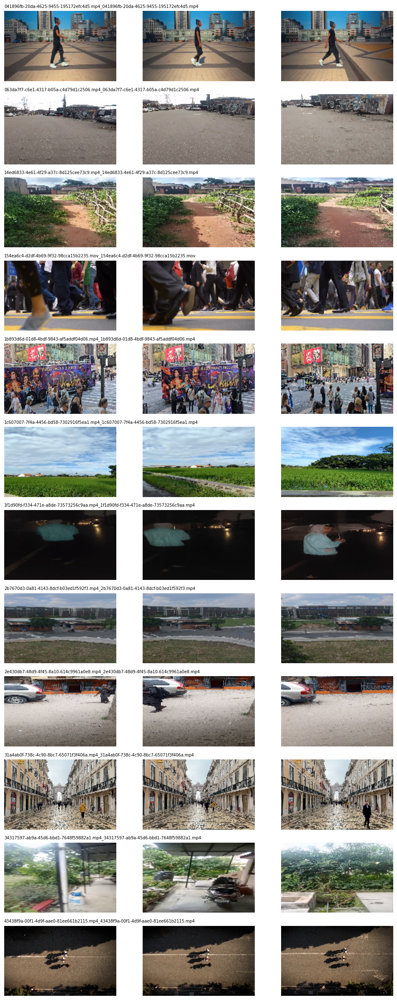

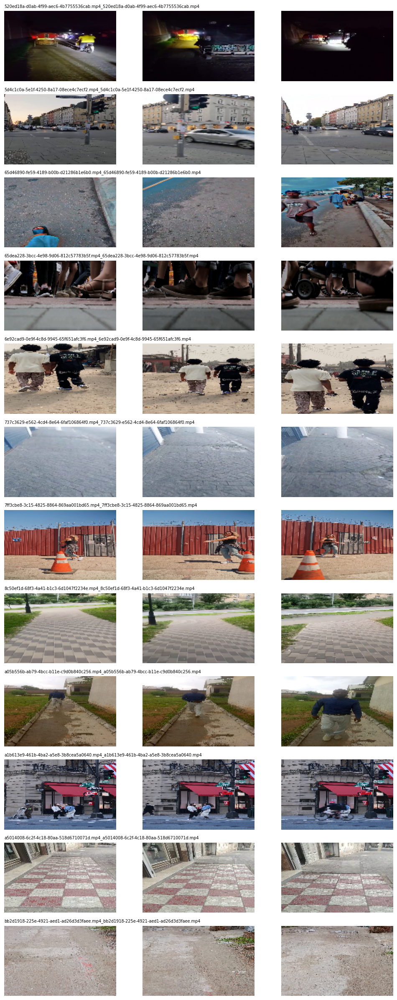

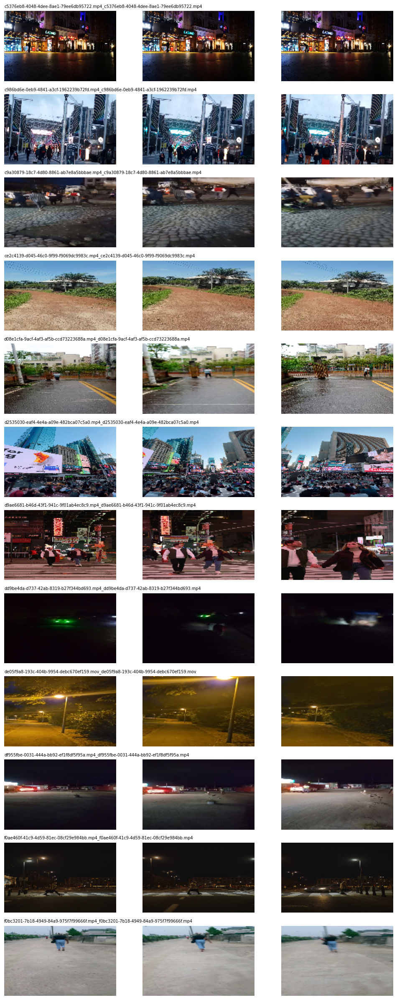

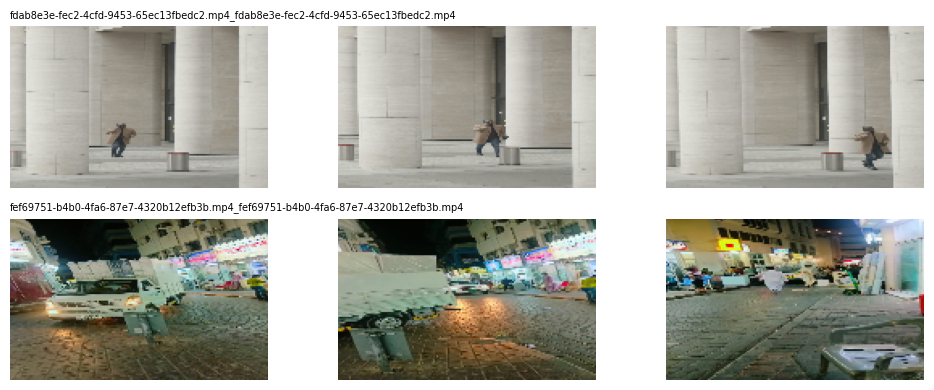

Contact sheets saved in: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU/results


In [ ]:
import math
import matplotlib.pyplot as plt
from PIL import Image

RAW_DIR = os.path.join(PROJECT_DIR, "dataset", "raw_unlabeled")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
FEATURE_DIR = os.path.join(PROJECT_DIR, "features")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FEATURE_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

video_paths = []
for root, dirs, files in os.walk(RAW_DIR):
    dirs[:] = [d for d in dirs if d != ".cache"]
    for name in files:
        if name.lower().endswith((".mp4", ".mov", ".avi", ".mkv")):
            video_paths.append(os.path.join(root, name))

video_paths = sorted(set(video_paths))
print("Videos found:", len(video_paths))

if len(video_paths) == 0:
    raise RuntimeError("No videos found. Check Step 3 before continuing.")

# Store relative paths so the labels remain easy to match
video_records = []
for path in video_paths:
    relpath = os.path.relpath(path, RAW_DIR)
    cap = cv2.VideoCapture(path)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    cap.release()

    video_records.append({
        "video": relpath,
        "frames": frame_count,
        "fps": round(fps, 2) if fps else 0
    })

video_df = pd.DataFrame(video_records)
display(video_df.head(20))

# Make contact sheets, 12 videos per sheet, 3 frames per video
def sample_frames(path, count=3):
    cap = cv2.VideoCapture(path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = []
    if total > 0:
        for idx in [int(total * p) for p in (0.2, 0.5, 0.8)]:
            cap.set(cv2.CAP_PROP_POS_FRAMES, min(idx, total - 1))
            ok, frame = cap.read()
            if ok:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frames.append(cv2.resize(frame, (160, 100)))
    cap.release()
    return frames

for start in range(0, len(video_paths), 12):
    batch = video_paths[start:start + 12]
    fig, axes = plt.subplots(len(batch), 3, figsize=(10, 2.0 * len(batch)))
    if len(batch) == 1:
        axes = [axes]

    for row, path in enumerate(batch):
        frames = sample_frames(path)
        for col in range(3):
            ax = axes[row][col]
            ax.axis("off")
            if col < len(frames):
                ax.imshow(frames[col])
            if col == 0:
                ax.set_title(os.path.relpath(path, RAW_DIR), fontsize=7, loc="left")

    plt.tight_layout()
    sheet_path = os.path.join(RESULTS_DIR, f"contact_sheet_{start//12 + 1}.png")
    plt.savefig(sheet_path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close()

print("Contact sheets saved in:", RESULTS_DIR)


#Label the videos as Uncrowded or Crowded

In [ ]:

# Step 5 (Fixed): Label videos interactively

import os
import cv2
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image

RAW_DIR = os.path.join(PROJECT_DIR, "dataset", "raw_unlabeled")
LABELS_FILE = os.path.join(PROJECT_DIR, "dataset", "video_labels.csv")

video_paths = []
for root, dirs, files in os.walk(RAW_DIR):
    dirs[:] = [d for d in dirs if d != ".cache"]
    for name in files:
        if name.lower().endswith((".mp4", ".mov", ".avi", ".mkv")):
            video_paths.append(os.path.join(root, name))

video_paths = sorted(set(video_paths))

if not video_paths:
    raise ValueError("No videos found. Check the Step 3 download.")

# Keep any labels you have already saved
if os.path.exists(LABELS_FILE):
    old_df = pd.read_csv(LABELS_FILE)
    labels = dict(zip(old_df["video"], old_df["label"]))
else:
    labels = {}

# Only show videos that have not been labeled
pending = [
    p for p in video_paths
    if os.path.relpath(p, RAW_DIR) not in labels
]

print("Total videos:", len(video_paths))
print("Already labeled:", len(labels))
print("Remaining to label:", len(pending))

if not pending:
    print("All videos are already labeled.")
else:
    state = {"index": 0}

    image_output = widgets.Output()
    progress = widgets.Label()
    uncrowded_btn = widgets.Button(description="Uncrowded", button_style="success")
    crowded_btn = widgets.Button(description="Crowded", button_style="danger")
    skip_btn = widgets.Button(description="Skip")
    save_btn = widgets.Button(description="Save labels", button_style="info")

    def save_current_labels():
        rows = [
            {"video": path, "label": label}
            for path, label in labels.items()
        ]
        pd.DataFrame(rows).to_csv(LABELS_FILE, index=False)

    def show_video():
        with image_output:
            clear_output(wait=True)

            if state["index"] >= len(pending):
                print("Finished reviewing all pending videos.")
                print("Click 'Save labels' to save your work.")
                progress.value = "Review complete"
                return

            path = pending[state["index"]]
            relpath = os.path.relpath(path, RAW_DIR)
            print("Video:", relpath)

            cap = cv2.VideoCapture(path)
            total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            frames = []

            if total > 0:
                for pos in [int(total * p) for p in (0.2, 0.5, 0.8)]:
                    cap.set(cv2.CAP_PROP_POS_FRAMES, min(pos, total - 1))
                    ok, frame = cap.read()
                    if ok:
                        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                        frames.append(Image.fromarray(frame))

            cap.release()

            for frame in frames:
                display(frame.resize((320, 200)))

            if not frames:
                print("Could not preview this video. Skip it.")

            progress.value = (
                f"Video {state['index'] + 1} of {len(pending)}"
            )

    def record_label(label):
        path = pending[state["index"]]
        relpath = os.path.relpath(path, RAW_DIR)

        if label in ("Uncrowded", "Crowded"):
            labels[relpath] = label

        state["index"] += 1
        show_video()

    uncrowded_btn.on_click(lambda _: record_label("Uncrowded"))
    crowded_btn.on_click(lambda _: record_label("Crowded"))
    skip_btn.on_click(lambda _: record_label("Skip"))
    save_btn.on_click(lambda _: save_current_labels())

    display(progress, image_output)
    display(widgets.HBox([uncrowded_btn, crowded_btn, skip_btn, save_btn]))
    show_video()


Total videos: 38
Already labeled: 0
Remaining to label: 38


Label(value='')

Output()

#Split the dataset into training, validation and test sets

In [ ]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Define the project and labels file paths
PROJECT_DIR = "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU"
labels_csv = os.path.join(PROJECT_DIR, "dataset", "video_labels.csv")

# Load video labels
labels_df = pd.read_csv(labels_csv)

# Keep only valid labels
labels_df["label"] = labels_df["label"].astype(str).str.strip().str.title()
labels_df = labels_df[labels_df["label"].isin(["Uncrowded", "Crowded"])]

# Check class counts
counts = labels_df["label"].value_counts()
print("Class counts:")
print(counts)

if len(counts) != 2 or counts.min() < 5:
    raise ValueError(
        "Please label at least 5 videos in each class: "
        "Uncrowded and Crowded."
    )

# Split: 70% training, 15% validation, 15% testing
train_df, temp_df = train_test_split(
    labels_df,
    test_size=0.30,
    random_state=42,
    stratify=labels_df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Save split files
train_df.to_csv(os.path.join(PROJECT_DIR, "dataset", "train.csv"), index=False)
val_df.to_csv(os.path.join(PROJECT_DIR, "dataset", "validation.csv"), index=False)
test_df.to_csv(os.path.join(PROJECT_DIR, "dataset", "test.csv"), index=False)

print("\nTraining videos:", len(train_df))
print("Validation videos:", len(val_df))
print("Testing videos:", len(test_df))
print("\nTraining class counts:")
print(train_df["label"].value_counts())
print("\nDataset split completed successfully!")


Class counts:
label
Crowded      24
Uncrowded    14
Name: count, dtype: int64

Training videos: 26
Validation videos: 6
Testing videos: 6

Training class counts:
label
Crowded      16
Uncrowded    10
Name: count, dtype: int64

Dataset split completed successfully!


#Extract frame features using a pretrained CNN

In [ ]:

import os
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from torchvision import models, transforms
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

NUM_FRAMES = 12
IMAGE_SIZE = 224

weights = models.ResNet18_Weights.DEFAULT
cnn = models.resnet18(weights=weights)
cnn.fc = nn.Identity()
cnn = cnn.to(device).eval()

preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

@torch.no_grad()
def extract_video_features(video_path):
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total <= 0:
        cap.release()
        raise ValueError("Video has no readable frames")

    positions = np.linspace(0, total - 1, NUM_FRAMES).astype(int)
    frames = []

    for position in positions:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(position))
        ok, frame = cap.read()

        if ok:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(preprocess(Image.fromarray(frame)))

    cap.release()

    if not frames:
        raise ValueError("Could not decode video frames")

    while len(frames) < NUM_FRAMES:
        frames.append(frames[-1].clone())

    batch = torch.stack(frames).to(device)
    features = cnn(batch).cpu().numpy().astype(np.float16)
    return features

# Load previously saved features if they exist
feature_file = os.path.join(FEATURE_DIR, "resnet18_video_features.npz")
key_file = os.path.join(FEATURE_DIR, "feature_video_paths.csv")

feature_map = {}

if os.path.exists(feature_file) and os.path.exists(key_file):
    saved = np.load(feature_file)
    saved_paths = pd.read_csv(key_file)["video"].tolist()

    for i, path in enumerate(saved_paths):
        key = f"video_{i}"
        if key in saved:
            feature_map[path] = saved[key]

    saved.close()

print("Previously saved features:", len(feature_map))

# Extract only videos whose features are missing
all_labeled = pd.concat(
    [train_df, val_df, test_df], ignore_index=True
).drop_duplicates(subset=["video"])

failed_videos = []

for _, row in tqdm(all_labeled.iterrows(), total=len(all_labeled)):
    relpath = row["video"]

    if relpath in feature_map:
        continue

    full_path = os.path.join(RAW_DIR, relpath)

    try:
        feature_map[relpath] = extract_video_features(full_path)
    except Exception as e:
        print("Failed:", relpath, "|", str(e))
        failed_videos.append(relpath)

# Save all successfully extracted features
feature_keys = list(feature_map.keys())

np.savez_compressed(
    feature_file,
    **{
        f"video_{i}": feature_map[path]
        for i, path in enumerate(feature_keys)
    }
)

pd.DataFrame({"video": feature_keys}).to_csv(key_file, index=False)

print("\nFeature extraction completed.")
print("Successful videos:", len(feature_map))
print("Failed videos:", len(failed_videos))

if feature_map:
    print("Feature shape per video:", next(iter(feature_map.values())).shape)

print("Features saved to:", feature_file)

if failed_videos:
    print("Some videos failed. Check the messages above before training.")


Using: cuda
Previously saved features: 0


  0%|          | 0/38 [00:00<?, ?it/s]


Feature extraction completed.
Successful videos: 38
Failed videos: 0
Feature shape per video: (12, 512)
Features saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU/features/resnet18_video_features.npz


#Train and compare RNN, LSTM and GRU

Using device: cuda
Videos with saved features: 38

Training RNN with 4 frames
Usable videos - Train: 26, Validation: 6, Test: 6
Epoch 01/15 | Train Loss: 0.7133 | Val Loss: 0.5195
Epoch 02/15 | Train Loss: 0.5450 | Val Loss: 0.4676
Epoch 03/15 | Train Loss: 0.4369 | Val Loss: 0.4339
Epoch 04/15 | Train Loss: 0.3770 | Val Loss: 0.4016
Epoch 05/15 | Train Loss: 0.3156 | Val Loss: 0.3692
Epoch 06/15 | Train Loss: 0.3396 | Val Loss: 0.3358
Epoch 07/15 | Train Loss: 0.2026 | Val Loss: 0.3091
Epoch 08/15 | Train Loss: 0.1879 | Val Loss: 0.2936
Epoch 09/15 | Train Loss: 0.1423 | Val Loss: 0.2765
Epoch 10/15 | Train Loss: 0.1211 | Val Loss: 0.2695
Epoch 11/15 | Train Loss: 0.1171 | Val Loss: 0.2367
Epoch 12/15 | Train Loss: 0.0798 | Val Loss: 0.2206
Epoch 13/15 | Train Loss: 0.0784 | Val Loss: 0.2089
Epoch 14/15 | Train Loss: 0.0547 | Val Loss: 0.2188
Epoch 15/15 | Train Loss: 0.0452 | Val Loss: 0.2409

Test results:
model: RNN
sequence_length: 4
accuracy: 1.0000
precision: 1.0000
recall: 1.00

,model,sequence_length,accuracy,precision,recall,f1,parameters,train_seconds,inference_ms_per_video,test_videos
0,RNN,4,1.0,1.0,1.0,1.0,37122,1.1997,0.0988,6
1,LSTM,4,1.0,1.0,1.0,1.0,148098,0.2479,0.0959,6
2,GRU,4,1.0,1.0,1.0,1.0,111106,0.3072,0.0952,6
3,RNN,8,1.0,1.0,1.0,1.0,37122,0.2163,0.0868,6
4,LSTM,8,1.0,1.0,1.0,1.0,148098,0.1574,0.1074,6
5,GRU,8,1.0,1.0,1.0,1.0,111106,0.2719,0.0876,6
6,RNN,12,1.0,1.0,1.0,1.0,37122,0.1500,0.0752,6
7,LSTM,12,1.0,1.0,1.0,1.0,148098,0.1597,0.0558,6
8,GRU,12,1.0,1.0,1.0,1.0,111106,0.1508,0.0792,6


Comparison saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU/results/model_comparison.csv
Trained models saved in: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU/models


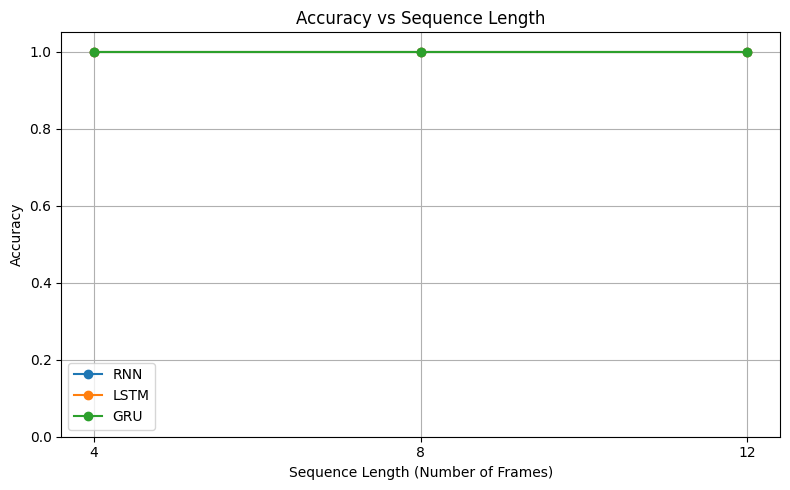

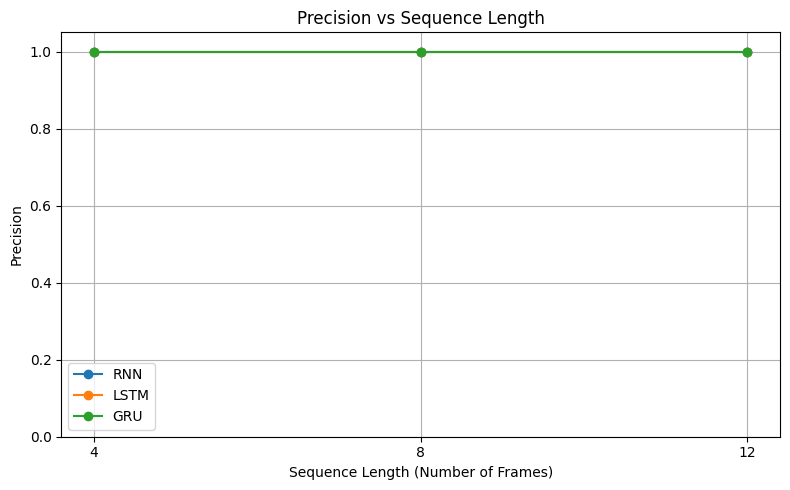

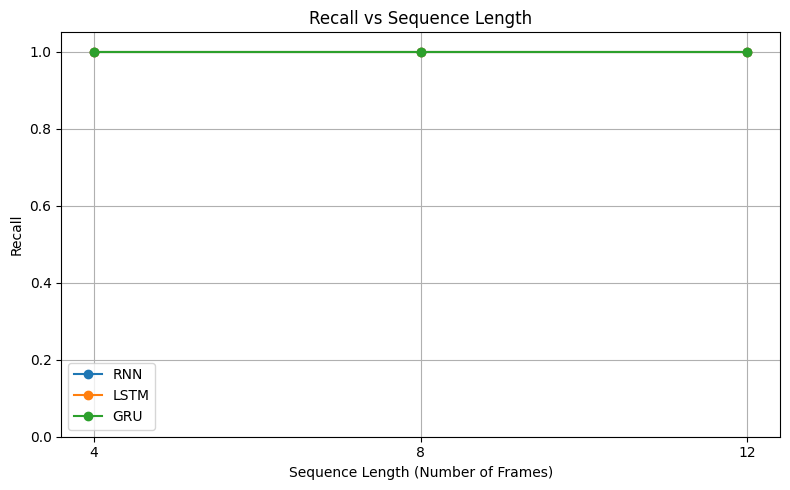

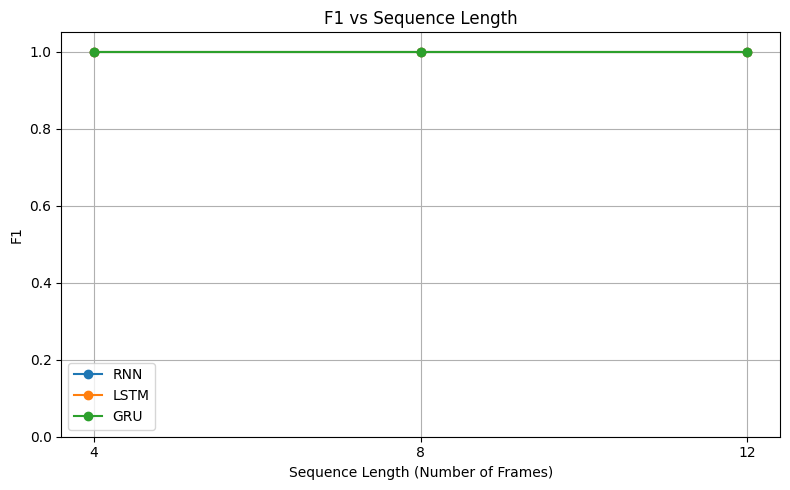

Performance plots saved in: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU/results

RNN Classification Report (12 frames)
              precision    recall  f1-score   support

   Uncrowded       1.00      1.00      1.00         2
     Crowded       1.00      1.00      1.00         4

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



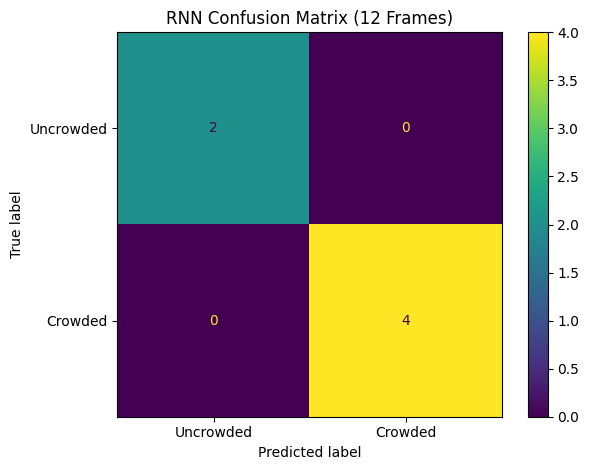


LSTM Classification Report (12 frames)
              precision    recall  f1-score   support

   Uncrowded       1.00      1.00      1.00         2
     Crowded       1.00      1.00      1.00         4

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



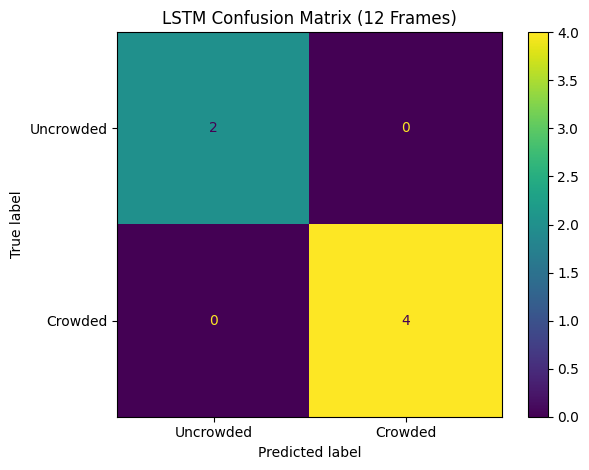


GRU Classification Report (12 frames)
              precision    recall  f1-score   support

   Uncrowded       1.00      1.00      1.00         2
     Crowded       1.00      1.00      1.00         4

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



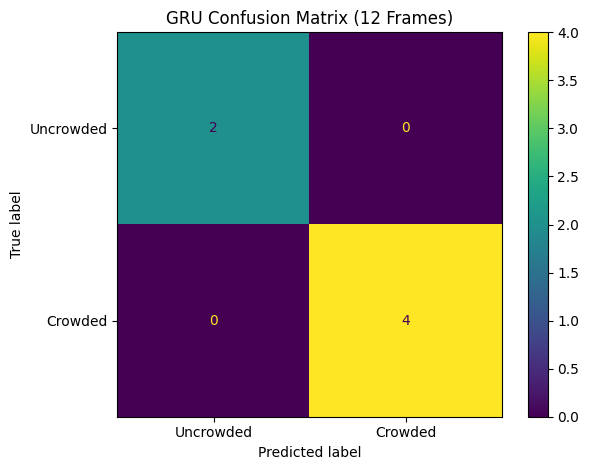


All experiments completed.
Check the results folder: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU/results


In [ ]:

# ============================================================
# Assignment 16: RNN vs LSTM vs GRU Video Classification
# Classes: Uncrowded and Crowded
# ============================================================

import os
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
from torch.utils.data import TensorDataset, DataLoader

# ------------------------------------------------------------
# 1. Set random seeds and device
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ------------------------------------------------------------
# 2. Define paths
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU"

FEATURE_DIR = os.path.join(PROJECT_DIR, "features")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

feature_file = os.path.join(
    FEATURE_DIR, "resnet18_video_features.npz"
)
key_file = os.path.join(
    FEATURE_DIR, "feature_video_paths.csv"
)

# ------------------------------------------------------------
# 3. Check required files and data splits
# ------------------------------------------------------------

if not os.path.exists(feature_file):
    raise FileNotFoundError(
        "Feature file not found. Run the feature extraction cell first."
    )

if not os.path.exists(key_file):
    raise FileNotFoundError(
        "Feature path file not found. Run the feature extraction cell first."
    )

for split_name in ["train_df", "val_df", "test_df"]:
    if split_name not in globals():
        raise NameError(
            f"{split_name} is missing. Run the dataset split cell first."
        )

# ------------------------------------------------------------
# 4. Load saved video features
# ------------------------------------------------------------

saved = np.load(feature_file)
saved_paths = pd.read_csv(key_file)["video"].tolist()

features_by_video = {}

for i, path in enumerate(saved_paths):
    key = f"video_{i}"

    if key in saved:
        features_by_video[path] = saved[key].astype(np.float32)

saved.close()

print("Videos with saved features:", len(features_by_video))

if len(features_by_video) == 0:
    raise ValueError(
        "No features were loaded. Run the feature extraction cell again."
    )

LABEL_TO_ID = {"Uncrowded": 0, "Crowded": 1}
ID_TO_LABEL = {0: "Uncrowded", 1: "Crowded"}

# ------------------------------------------------------------
# 5. Prepare sequences and labels
# ------------------------------------------------------------

def make_xy(split_df, sequence_length):
    xs, ys, names = [], [], []

    for _, row in split_df.iterrows():
        path = row["video"]
        label = str(row["label"]).strip().title()

        if label not in LABEL_TO_ID:
            continue

        if path not in features_by_video:
            continue

        seq = features_by_video[path]

        if seq.ndim != 2 or seq.shape[1] != 512:
            print("Skipping invalid feature shape:", path, seq.shape)
            continue

        indices = np.linspace(
            0, len(seq) - 1, sequence_length
        ).astype(int)

        xs.append(seq[indices])
        ys.append(LABEL_TO_ID[label])
        names.append(path)

    if not xs:
        raise ValueError(
            f"No usable videos in the split for sequence length {sequence_length}. "
            "Check labels and extracted features."
        )

    return (
        torch.tensor(np.stack(xs), dtype=torch.float32),
        torch.tensor(ys, dtype=torch.long),
        names
    )


# ------------------------------------------------------------
# 6. Define RNN, LSTM, and GRU model
# ------------------------------------------------------------

class VideoRNN(nn.Module):
    def __init__(self, kind, input_size=512, hidden_size=64):
        super().__init__()
        self.kind = kind

        if kind == "RNN":
            self.temporal = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                batch_first=True
            )
        elif kind == "LSTM":
            self.temporal = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                batch_first=True
            )
        elif kind == "GRU":
            self.temporal = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                batch_first=True
            )
        else:
            raise ValueError("Model must be RNN, LSTM, or GRU.")

        self.classifier = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(hidden_size, 2)
        )

    def forward(self, x):
        # All three layers return (sequence_output, hidden_state).
        sequence_output, _ = self.temporal(x)

        # Use the final time step to classify the video.
        last_output = sequence_output[:, -1, :]

        return self.classifier(last_output)


# ------------------------------------------------------------
# 7. Train and evaluate one model
# ------------------------------------------------------------

def train_one_model(kind, sequence_length, epochs=15):

    X_train, y_train, _ = make_xy(train_df, sequence_length)
    X_val, y_val, _ = make_xy(val_df, sequence_length)
    X_test, y_test, test_names = make_xy(test_df, sequence_length)

    print(
        f"Usable videos - Train: {len(y_train)}, "
        f"Validation: {len(y_val)}, Test: {len(y_test)}"
    )

    if len(torch.unique(y_train)) < 2:
        raise ValueError(
            "Training data must contain both Uncrowded and Crowded classes."
        )

    if len(torch.unique(y_val)) < 2:
        print(
            "Warning: Validation data contains only one class. "
            "Results may be less reliable."
        )

    train_loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=8,
        shuffle=True
    )

    model = VideoRNN(kind).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_state = None
    patience = 4
    wait = 0

    start_train = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)
            loss = loss_fn(logits, yb)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        model.eval()

        with torch.no_grad():
            val_logits = model(X_val.to(device))
            val_loss = loss_fn(
                val_logits, y_val.to(device)
            ).item()

        avg_train_loss = total_loss / max(len(train_loader), 1)

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1

            if wait >= patience:
                print("Early stopping.")
                break

    train_seconds = time.perf_counter() - start_train

    if best_state is None:
        raise RuntimeError("Training did not produce a valid model.")

    model.load_state_dict(best_state)
    model.eval()

    # --------------------------------------------------------
    # 8. Measure inference time
    # --------------------------------------------------------

    xb = X_test.to(device)

    with torch.no_grad():
        for _ in range(3):
            _ = model(xb)

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_inference = time.perf_counter()
        logits = model(xb)

        if device.type == "cuda":
            torch.cuda.synchronize()

        inference_seconds = time.perf_counter() - start_inference

    predictions = logits.argmax(dim=1).cpu().numpy()
    truth = y_test.numpy()

    # --------------------------------------------------------
    # 9. Calculate metrics
    # --------------------------------------------------------

    result = {
        "model": kind,
        "sequence_length": sequence_length,
        "accuracy": accuracy_score(truth, predictions),
        "precision": precision_score(
            truth, predictions, zero_division=0
        ),
        "recall": recall_score(
            truth, predictions, zero_division=0
        ),
        "f1": f1_score(
            truth, predictions, zero_division=0
        ),
        "parameters": sum(
            p.numel() for p in model.parameters()
        ),
        "train_seconds": train_seconds,
        "inference_ms_per_video": (
            inference_seconds / max(len(truth), 1) * 1000
        ),
        "test_videos": len(truth),
        "confusion_matrix": confusion_matrix(
            truth, predictions, labels=[0, 1]
        ).tolist()
    }

    return model, result, truth, predictions, test_names


# ------------------------------------------------------------
# 10. Run all nine experiments
# ------------------------------------------------------------

all_results = []
trained_models = {}
test_outputs = {}

for seq_len in [4, 8, 12]:
    for kind in ["RNN", "LSTM", "GRU"]:

        print("\n" + "=" * 55)
        print(f"Training {kind} with {seq_len} frames")
        print("=" * 55)

        model, result, truth, pred, names = train_one_model(
            kind, seq_len
        )

        all_results.append(result)
        trained_models[(kind, seq_len)] = model
        test_outputs[(kind, seq_len)] = (truth, pred, names)

        model_path = os.path.join(
            MODEL_DIR, f"{kind.lower()}_{seq_len}_frames.pt"
        )

        torch.save(
            model.cpu().state_dict(),
            model_path
        )
        model.to(device)

        print("\nTest results:")
        for key, value in result.items():
            if key == "confusion_matrix":
                continue
            if isinstance(value, float):
                print(f"{key}: {value:.4f}")
            else:
                print(f"{key}: {value}")


# ------------------------------------------------------------
# 11. Save comparison table
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

results_csv = os.path.join(
    RESULTS_DIR, "model_comparison.csv"
)
results_df.to_csv(results_csv, index=False)

print("\n" + "=" * 65)
print("FINAL MODEL COMPARISON")
print("=" * 65)

display(results_df[[
    "model",
    "sequence_length",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "parameters",
    "train_seconds",
    "inference_ms_per_video",
    "test_videos"
]].round(4))

print("Comparison saved to:", results_csv)
print("Trained models saved in:", MODEL_DIR)


# ------------------------------------------------------------
# 12. Plot performance comparison
# ------------------------------------------------------------

for metric in ["accuracy", "precision", "recall", "f1"]:
    plt.figure(figsize=(8, 5))

    for kind in ["RNN", "LSTM", "GRU"]:
        subset = results_df[results_df["model"] == kind]

        plt.plot(
            subset["sequence_length"],
            subset[metric],
            marker="o",
            label=kind
        )

    plt.xlabel("Sequence Length (Number of Frames)")
    plt.ylabel(metric.capitalize())
    plt.title(f"{metric.capitalize()} vs Sequence Length")
    plt.xticks([4, 8, 12])
    plt.ylim(0, 1.05)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    plot_path = os.path.join(
        RESULTS_DIR, f"{metric}_comparison.png"
    )
    plt.savefig(plot_path, dpi=150)
    plt.show()
    plt.close()

print("Performance plots saved in:", RESULTS_DIR)


# ------------------------------------------------------------
# 13. Display confusion matrices and classification reports
# ------------------------------------------------------------

for kind in ["RNN", "LSTM", "GRU"]:
    key = (kind, 12)

    if key not in test_outputs:
        continue

    truth, pred, names = test_outputs[key]

    print("\n" + "=" * 55)
    print(f"{kind} Classification Report (12 frames)")
    print("=" * 55)

    print(classification_report(
        truth,
        pred,
        labels=[0, 1],
        target_names=["Uncrowded", "Crowded"],
        zero_division=0
    ))

    cm = confusion_matrix(truth, pred, labels=[0, 1])

    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Uncrowded", "Crowded"]
    )

    display_obj.plot()
    plt.title(f"{kind} Confusion Matrix (12 Frames)")
    plt.tight_layout()

    cm_path = os.path.join(
        RESULTS_DIR, f"{kind.lower()}_confusion_matrix.png"
    )
    plt.savefig(cm_path, dpi=150)
    plt.show()
    plt.close()

print("\nAll experiments completed.")
print("Check the results folder:", RESULTS_DIR)


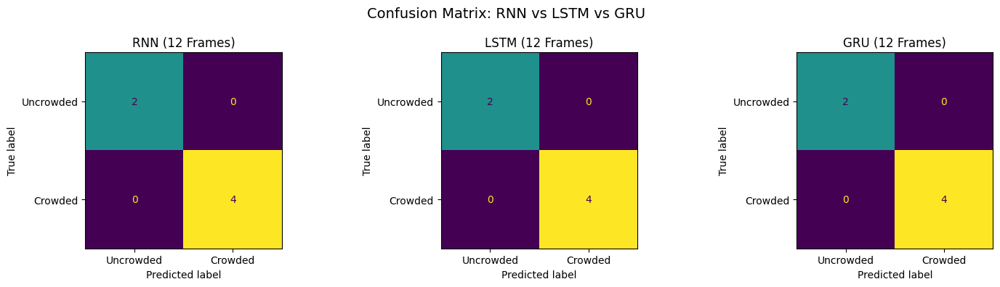

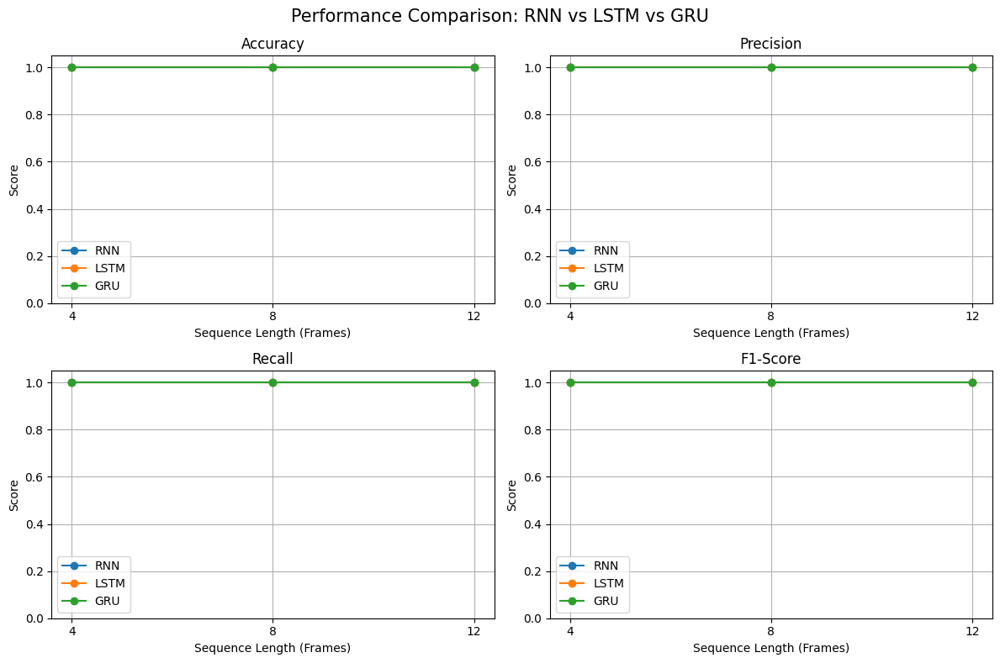

Both figures saved successfully!
1. all_confusion_matrices.png
2. all_performance_graphs.png


In [ ]:
# ============================================================
# 1. All 3 Confusion Matrices in One Figure
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, kind in enumerate(["RNN", "LSTM", "GRU"]):
    truth, pred, names = test_outputs[(kind, 12)]

    cm = confusion_matrix(truth, pred, labels=[0, 1])

    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Uncrowded", "Crowded"]
    )

    display_obj.plot(ax=axes[i], colorbar=False, values_format="d")
    axes[i].set_title(f"{kind} (12 Frames)")

plt.suptitle("Confusion Matrix: RNN vs LSTM vs GRU", fontsize=14)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "all_confusion_matrices.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 2. Accuracy, Precision, Recall, and F1 in One Figure
# ============================================================

metrics = ["accuracy", "precision", "recall", "f1"]
metric_titles = ["Accuracy", "Precision", "Recall", "F1-Score"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    for kind in ["RNN", "LSTM", "GRU"]:
        subset = results_df[results_df["model"] == kind].sort_values(
            "sequence_length"
        )

        axes[i].plot(
            subset["sequence_length"],
            subset[metric],
            marker="o",
            label=kind
        )

    axes[i].set_title(metric_titles[i])
    axes[i].set_xlabel("Sequence Length (Frames)")
    axes[i].set_ylabel("Score")
    axes[i].set_xticks([4, 8, 12])
    axes[i].set_ylim(0, 1.05)
    axes[i].grid(True)
    axes[i].legend()

plt.suptitle(
    "Performance Comparison: RNN vs LSTM vs GRU",
    fontsize=15
)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "all_performance_graphs.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Both figures saved successfully!")
print("1. all_confusion_matrices.png")
print("2. all_performance_graphs.png")

#Compare frame-level and video-level classification

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import os

# Use 12-frame features for this comparison
def prepare_frame_data(split_df):
    X, y = [], []

    for _, row in split_df.iterrows():
        path = row["video"]
        label = str(row["label"]).strip().title()

        if path not in features_by_video or label not in LABEL_TO_ID:
            continue

        for frame_feature in features_by_video[path]:
            X.append(frame_feature)
            y.append(LABEL_TO_ID[label])

    return np.asarray(X), np.asarray(y)

X_train_frame, y_train_frame = prepare_frame_data(train_df)
X_test_frame, y_test_frame = prepare_frame_data(test_df)

if len(X_train_frame) == 0 or len(X_test_frame) == 0:
    raise ValueError("No usable frame features. Check your dataset and features.")

frame_classifier = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)
frame_classifier.fit(X_train_frame, y_train_frame)

frame_predictions = frame_classifier.predict(X_test_frame)

frame_results = {
    "evaluation": "Individual frames",
    "accuracy": accuracy_score(y_test_frame, frame_predictions),
    "precision": precision_score(y_test_frame, frame_predictions, zero_division=0),
    "recall": recall_score(y_test_frame, frame_predictions, zero_division=0),
    "f1": f1_score(y_test_frame, frame_predictions, zero_division=0)
}

# Whole-video predictions: average frame probabilities within each video
video_truth, video_predictions = [], []

for _, row in test_df.iterrows():
    path = row["video"]
    label = str(row["label"]).strip().title()

    if path not in features_by_video or label not in LABEL_TO_ID:
        continue

    frame_features = features_by_video[path].astype(np.float32)
    probabilities = frame_classifier.predict_proba(frame_features)
    average_probability = probabilities.mean(axis=0)

    video_predictions.append(int(np.argmax(average_probability)))
    video_truth.append(LABEL_TO_ID[label])

video_results = {
    "evaluation": "Whole videos (averaged frame probabilities)",
    "accuracy": accuracy_score(video_truth, video_predictions),
    "precision": precision_score(video_truth, video_predictions, zero_division=0),
    "recall": recall_score(video_truth, video_predictions, zero_division=0),
    "f1": f1_score(video_truth, video_predictions, zero_division=0)
}

comparison_df = pd.DataFrame([frame_results, video_results])
display(comparison_df.round(4))

comparison_df.to_csv(
    os.path.join(RESULTS_DIR, "frame_vs_video_comparison.csv"),
    index=False
)

print("Saved frame vs video comparison.")


,evaluation,accuracy,precision,recall,f1
0,Individual frames,0.9028,0.8868,0.9792,0.9307
1,Whole videos (averaged frame probabilities),0.8333,0.8000,1.0000,0.8889


Saved frame vs video comparison.


#Create a video index

In [ ]:


kind = "GRU"
sequence_length = 12

model = trained_models[(kind, sequence_length)]
model.eval()

index_rows = []

all_labeled = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
).drop_duplicates(subset=["video"])

for _, row in all_labeled.iterrows():
    path = row["video"]
    true_label = str(row["label"]).strip().title()

    if path not in features_by_video or true_label not in LABEL_TO_ID:
        continue

    seq = features_by_video[path]
    indices = np.linspace(0, len(seq) - 1, sequence_length).astype(int)
    x = torch.tensor(seq[indices], dtype=torch.float32).unsqueeze(0).to(device)

    with torch.no_grad():
        probabilities = torch.softmax(model(x), dim=1)[0].cpu().numpy()

    predicted_id = int(np.argmax(probabilities))

    index_rows.append({
        "video": path,
        "true_label": true_label,
        "predicted_label": ID_TO_LABEL[predicted_id],
        "uncrowded_probability": float(probabilities[0]),
        "crowded_probability": float(probabilities[1])
    })

video_index_df = pd.DataFrame(index_rows)

index_path = os.path.join(RESULTS_DIR, "video_index.csv")
video_index_df.to_csv(index_path, index=False)

display(video_index_df.head(10))
print("Video index saved to:", index_path)


,video,true_label,predicted_label,uncrowded_probability,crowded_probability
0,34317597-ab9a-45d6-bbd1-7648f59882a1.mp4_34317...,Uncrowded,Uncrowded,0.984954,0.015046
1,31a4ab0f-738c-4c90-8bc7-65071f3f406a.mp4_31a4a...,Crowded,Crowded,0.015847,0.984153
2,65d46890-fe59-4189-b00b-d21286b1e6b0.mp4_65d46...,Crowded,Crowded,0.020847,0.979153
3,6e92cad9-0e9f-4c8d-9945-65f651afc3f6.mp4_6e92c...,Crowded,Crowded,0.020531,0.979469
4,c5376eb8-4048-4dee-8ae1-79ee6db95722.mp4_c5376...,Crowded,Crowded,0.036136,0.963864
5,1b893d6d-01d8-4bdf-9843-af5addf04d06.mp4_1b893...,Crowded,Crowded,0.010369,0.989631
6,14ed6833-4e61-4f29-a37c-8d125cee73c9.mp4_14ed6...,Uncrowded,Uncrowded,0.979216,0.020784
7,f0bc3201-7b18-4949-84a9-975f7f99666f.mp4_f0bc3...,Crowded,Crowded,0.105019,0.894981
8,5d4c1c0a-5e1f-4250-8a17-08ece4c7ecf2.mp4_5d4c1...,Crowded,Crowded,0.039008,0.960992
9,041896fb-20da-4625-9455-195172efc4d5.mp4_04189...,Crowded,Crowded,0.009067,0.990932


Video index saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU/results/video_index.csv


#Search and retrieve videos

In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output
from IPython.display import Video as NotebookVideo

search_class = widgets.Dropdown(
    options=["All", "Uncrowded", "Crowded"],
    value="All",
    description="Class:"
)

search_button = widgets.Button(
    description="Search Videos",
    button_style="primary"
)

output = widgets.Output()

def search_videos(_):
    with output:
        clear_output()

        if search_class.value == "All":
            results = video_index_df
        else:
            results = video_index_df[
                video_index_df["predicted_label"] == search_class.value
            ]

        if results.empty:
            print("No matching videos found.")
            return

        print("Matching videos:", len(results))

        for _, item in results.iterrows():
            print("\nVideo:", item["video"])
            print("Actual label:", item["true_label"])
            print("Predicted label:", item["predicted_label"])

            video_path = os.path.join(RAW_DIR, item["video"])

            if os.path.exists(video_path):
                display(NotebookVideo(video_path, embed=False))

search_button.on_click(search_videos)

display(search_class, search_button, output)


Dropdown(description='Class:', options=('All', 'Uncrowded', 'Crowded'), value='All')

Button(button_style='primary', description='Search Videos', style=ButtonStyle())

Output()

#Save the final summary

In [ ]:

summary_path = os.path.join(RESULTS_DIR, "assignment16_summary.txt")

with open(summary_path, "w") as f:
    f.write("Assignment 16: RNN, LSTM and GRU Video Classification\n")
    f.write("Classes: Uncrowded and Crowded\n\n")

    f.write(f"Labeled videos: {len(all_labeled)}\n")
    f.write(f"Videos with extracted features: {len(features_by_video)}\n\n")

    f.write("Model comparison:\n")
    f.write(results_df.to_string(index=False))
    f.write("\n\nFrame-level vs video-level comparison:\n")
    f.write(comparison_df.to_string(index=False))
    f.write("\n")

print("Summary saved to:", summary_path)
print("\nResults folder contents:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print("-", filename)


Summary saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment16_RNN_LSTM_GRU/results/assignment16_summary.txt

Results folder contents:
- accuracy_comparison.png
- all_confusion_matrices.png
- all_performance_graphs.png
- assignment16_summary.txt
- contact_sheet_1.png
- contact_sheet_2.png
- contact_sheet_3.png
- contact_sheet_4.png
- experiment_summary.json
- f1_comparison.png
- frame_vs_video_comparison.csv
- gru_confusion_matrix.png
- lstm_confusion_matrix.png
- model_comparison.csv
- precision_comparison.png
- recall_comparison.png
- rnn_confusion_matrix.png
- video_index.csv
